Step 1: Connect to BigQuery using sqlalchemy

In [14]:
import os
from dotenv import load_dotenv
import pandas as pd
from sqlalchemy import create_engine

# Load environment variables from .env
load_dotenv()

project_id = os.getenv("GCP_PROJECT_ID")
dataset_id = os.getenv("GCP_DATASET_ID")

# SQLAlchemy BigQuery connection URI: bigquery://<project_id>/<dataset_id>
engine = create_engine(f"bigquery://{project_id}/{dataset_id}")


Test querying the table and fetch into Pandas DataFrame. View table info.

In [15]:

# Simple query selecting recent prices and moving averages
query = f"""
    SELECT 
        ticker,
        date,
        close,
        sma_20,
        sma_50,
        daily_return
    FROM `{project_id}.{dataset_id}.fact_dailyprice`
    WHERE ticker = 'NVDA'
    ORDER BY date DESC
    LIMIT 10
"""

# Fetch into Pandas DataFrame
df = pd.read_sql(query, con=engine)

print("DataFrame Output:")
print(df)
print("\nDataFrame Info:")
print(df.dtypes)

DataFrame Output:
  ticker        date   close    sma_20    sma_50  daily_return
0   NVDA  2026-10-08  236.10  226.4655  221.5050     -0.005769
1   NVDA  2026-10-07  237.47  225.5785  220.5832     -0.007398
2   NVDA  2026-10-06  239.24  224.8885  219.7740      0.001423
3   NVDA  2026-10-05  238.90  224.2130  218.9194      0.021158
4   NVDA  2026-10-02  233.95  223.7860  218.2782      0.013385
5   NVDA  2026-10-01  230.86  223.5110  217.7744      0.010859
6   NVDA  2026-09-30  228.38  223.1885  217.3984      0.005149
7   NVDA  2026-09-29  227.21  222.6415  216.9766     -0.007210
8   NVDA  2026-09-28  228.86  222.3200  216.4980      0.016839
9   NVDA  2026-09-25  225.07  221.7545  215.9770      0.002182

DataFrame Info:
ticker           object
date             object
close           float64
sma_20          float64
sma_50          float64
daily_return    float64
dtype: object


Check data count ensure its correct.

In [ ]:
query = f"""
    SELECT 
        count(*) as total_records
    FROM `{project_id}.{dataset_id}.fact_dailyprice`  
"""
query_cnt = pd.read_sql(query_cnt, con=engine)
query_cnt

,total_records
0,622710


Step 2: Query the full fact_dailyprice table and join with dim_ticker table to get tickers information. Then fetch into Pandas DataFrame.

In [3]:
# Simple query selecting recent prices and moving averages
query = f"""
    SELECT 
        a.*,
        b.*
    FROM `{project_id}.{dataset_id}.fact_dailyprice` a
    left JOIN `{project_id}.{dataset_id}.dim_ticker` b ON a.ticker = b.ticker
    ORDER BY a.ticker, a.date
"""

# Fetch into Pandas DataFrame
df1 = pd.read_sql(query, con=engine)

pd.set_option("display.max_columns", None)
df1

,date,ticker,date_added,fiscal_period_end,fund_filed,open,high,low,close,adj_close,volume,chg_pct,rel_vol,dividends,stock_splits,mkt_cap,pe,p_cfo,p_fcf,p_book,div_yield_pct,eps_diluted,eps_diluted_ttm,eps_ttm_yoy_pct,revenue_ps_ttm,revenue_ttm_yoy_pct,cfo_ps_ttm,fcf_ps_ttm,dps_ttm,book_value_ps,cash_ps,lt_debt_ps,assets_ps,liabilities_ps,shares_out,id,sma_20,sma_50,sma_100,sma_200,daily_return,ticker_1,company,sector,sub_industry
0,2021-10-06,A,2000-06-05,2021-07-31,2021-09-01,152.55,154.26,151.62,153.65,148.2560,1794700,0.41,1.15,0.0,0.0,4.655595e+10,48.02,33.09,37.08,9.41,0.51,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,1,NaN,NaN,NaN,NaN,NaN,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
1,2021-10-07,A,2000-06-05,2021-07-31,2021-09-01,155.06,157.48,154.96,155.32,149.8674,1002800,1.09,0.61,0.0,0.0,4.706196e+10,48.54,33.45,37.48,9.52,0.50,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,2,NaN,NaN,NaN,NaN,0.010869,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
2,2021-10-08,A,2000-06-05,2021-07-31,2021-09-01,156.18,156.92,152.10,152.47,147.1174,904100,-1.83,0.57,0.0,0.0,4.619841e+10,47.65,32.83,36.79,9.34,0.51,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,3,NaN,NaN,NaN,NaN,-0.018350,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
3,2021-10-11,A,2000-06-05,2021-07-31,2021-09-01,151.49,152.36,149.88,150.02,144.7535,1106300,-1.61,0.71,0.0,0.0,4.545606e+10,46.88,32.31,36.20,9.19,0.52,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,4,NaN,NaN,NaN,NaN,-0.016068,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
4,2021-10-12,A,2000-06-05,2021-07-31,2021-09-01,151.18,151.18,146.30,147.95,142.7561,1809900,-1.38,1.18,0.0,0.0,4.482885e+10,46.23,31.86,35.70,9.06,0.52,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,5,NaN,NaN,NaN,NaN,-0.013799,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
622684,2026-09-30,ZTS,2013-06-21,2026-06-30,2026-08-06,70.55,70.77,69.52,69.83,69.8300,4444300,-0.67,0.99,0.0,0.0,2.892038e+10,11.50,10.27,12.59,9.19,2.99,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622685,72.7085,74.5964,75.9637,98.85400,-0.006686,ZTS,Zoetis,Health Care,Pharmaceuticals
622685,2026-10-01,ZTS,2013-06-21,2026-06-30,2026-08-06,70.00,70.90,68.92,69.10,69.1000,5346600,-1.05,1.19,0.0,0.0,2.861804e+10,11.38,10.16,12.46,9.09,3.02,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622686,72.3550,74.4946,75.8264,98.60620,-0.010454,ZTS,Zoetis,Health Care,Pharmaceuticals
622686,2026-10-02,ZTS,2013-06-21,2026-06-30,2026-08-06,69.12,70.10,68.77,69.69,69.6900,5259300,0.85,1.14,0.0,0.0,2.886240e+10,11.48,10.25,12.57,9.17,3.00,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622687,72.0250,74.3970,75.7566,98.34975,0.008538,ZTS,Zoetis,Health Care,Pharmaceuticals
622687,2026-10-05,ZTS,2013-06-21,2026-06-30,2026-08-06,69.41,71.47,69.00,71.41,71.4100,3644100,2.47,0.88,0.0,0.0,2.957474e+10,11.76,10.50,12.88,9.39,2.93,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622688,71.8050,74.3182,75.7013,98.09065,0.024681,ZTS,Zoetis,Health Care,Pharmaceuticals


Convert dates fields into datetime format.

In [4]:
df1["date"] = pd.to_datetime(df1["date"])
df1["fiscal_period_end"] = pd.to_datetime(df1["fiscal_period_end"])
df1["fund_filed"] = pd.to_datetime(df1["fund_filed"])
df1["_month"] = df1["date"].dt.to_period("M")
display(df1.info())
df1

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 622689 entries, 0 to 622688
Data columns (total 46 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   date                 622689 non-null  datetime64[ns]
 1   ticker               622689 non-null  object        
 2   date_added           622689 non-null  object        
 3   fiscal_period_end    616922 non-null  datetime64[ns]
 4   fund_filed           616922 non-null  datetime64[ns]
 5   open                 622689 non-null  float64       
 6   high                 622689 non-null  float64       
 7   low                  622689 non-null  float64       
 8   close                622689 non-null  float64       
 9   adj_close            622689 non-null  float64       
 10  volume               622689 non-null  int64         
 11  chg_pct              622677 non-null  float64       
 12  rel_vol              622572 non-null  float64       
 13  dividends     

None

,date,ticker,date_added,fiscal_period_end,fund_filed,open,high,low,close,adj_close,volume,chg_pct,rel_vol,dividends,stock_splits,mkt_cap,pe,p_cfo,p_fcf,p_book,div_yield_pct,eps_diluted,eps_diluted_ttm,eps_ttm_yoy_pct,revenue_ps_ttm,revenue_ttm_yoy_pct,cfo_ps_ttm,fcf_ps_ttm,dps_ttm,book_value_ps,cash_ps,lt_debt_ps,assets_ps,liabilities_ps,shares_out,id,sma_20,sma_50,sma_100,sma_200,daily_return,ticker_1,company,sector,sub_industry,_month
0,2021-10-06,A,2000-06-05,2021-07-31,2021-09-01,152.55,154.26,151.62,153.65,148.2560,1794700,0.41,1.15,0.0,0.0,4.655595e+10,48.02,33.09,37.08,9.41,0.51,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,1,NaN,NaN,NaN,NaN,NaN,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2021-10
1,2021-10-07,A,2000-06-05,2021-07-31,2021-09-01,155.06,157.48,154.96,155.32,149.8674,1002800,1.09,0.61,0.0,0.0,4.706196e+10,48.54,33.45,37.48,9.52,0.50,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,2,NaN,NaN,NaN,NaN,0.010869,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2021-10
2,2021-10-08,A,2000-06-05,2021-07-31,2021-09-01,156.18,156.92,152.10,152.47,147.1174,904100,-1.83,0.57,0.0,0.0,4.619841e+10,47.65,32.83,36.79,9.34,0.51,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,3,NaN,NaN,NaN,NaN,-0.018350,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2021-10
3,2021-10-11,A,2000-06-05,2021-07-31,2021-09-01,151.49,152.36,149.88,150.02,144.7535,1106300,-1.61,0.71,0.0,0.0,4.545606e+10,46.88,32.31,36.20,9.19,0.52,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,4,NaN,NaN,NaN,NaN,-0.016068,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2021-10
4,2021-10-12,A,2000-06-05,2021-07-31,2021-09-01,151.18,151.18,146.30,147.95,142.7561,1809900,-1.38,1.18,0.0,0.0,4.482885e+10,46.23,31.86,35.70,9.06,0.52,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,5,NaN,NaN,NaN,NaN,-0.013799,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2021-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
622684,2026-09-30,ZTS,2013-06-21,2026-06-30,2026-08-06,70.55,70.77,69.52,69.83,69.8300,4444300,-0.67,0.99,0.0,0.0,2.892038e+10,11.50,10.27,12.59,9.19,2.99,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622685,72.7085,74.5964,75.9637,98.85400,-0.006686,ZTS,Zoetis,Health Care,Pharmaceuticals,2026-09
622685,2026-10-01,ZTS,2013-06-21,2026-06-30,2026-08-06,70.00,70.90,68.92,69.10,69.1000,5346600,-1.05,1.19,0.0,0.0,2.861804e+10,11.38,10.16,12.46,9.09,3.02,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622686,72.3550,74.4946,75.8264,98.60620,-0.010454,ZTS,Zoetis,Health Care,Pharmaceuticals,2026-10
622686,2026-10-02,ZTS,2013-06-21,2026-06-30,2026-08-06,69.12,70.10,68.77,69.69,69.6900,5259300,0.85,1.14,0.0,0.0,2.886240e+10,11.48,10.25,12.57,9.17,3.00,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622687,72.0250,74.3970,75.7566,98.34975,0.008538,ZTS,Zoetis,Health Care,Pharmaceuticals,2026-10
622687,2026-10-05,ZTS,2013-06-21,2026-06-30,2026-08-06,69.41,71.47,69.00,71.41,71.4100,3644100,2.47,0.88,0.0,0.0,2.957474e+10,11.76,10.50,12.88,9.39,2.93,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622688,71.8050,74.3182,75.7013,98.09065,0.024681,ZTS,Zoetis,Health Care,Pharmaceuticals,2026-10


Step 3: Make a copy to start extracting relevant fields.

In [5]:
dfm = df1.copy()
dfm

,date,ticker,date_added,fiscal_period_end,fund_filed,open,high,low,close,adj_close,volume,chg_pct,rel_vol,dividends,stock_splits,mkt_cap,pe,p_cfo,p_fcf,p_book,div_yield_pct,eps_diluted,eps_diluted_ttm,eps_ttm_yoy_pct,revenue_ps_ttm,revenue_ttm_yoy_pct,cfo_ps_ttm,fcf_ps_ttm,dps_ttm,book_value_ps,cash_ps,lt_debt_ps,assets_ps,liabilities_ps,shares_out,id,sma_20,sma_50,sma_100,sma_200,daily_return,ticker_1,company,sector,sub_industry,_month
0,2021-10-06,A,2000-06-05,2021-07-31,2021-09-01,152.55,154.26,151.62,153.65,148.2560,1794700,0.41,1.15,0.0,0.0,4.655595e+10,48.02,33.09,37.08,9.41,0.51,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,1,NaN,NaN,NaN,NaN,NaN,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2021-10
1,2021-10-07,A,2000-06-05,2021-07-31,2021-09-01,155.06,157.48,154.96,155.32,149.8674,1002800,1.09,0.61,0.0,0.0,4.706196e+10,48.54,33.45,37.48,9.52,0.50,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,2,NaN,NaN,NaN,NaN,0.010869,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2021-10
2,2021-10-08,A,2000-06-05,2021-07-31,2021-09-01,156.18,156.92,152.10,152.47,147.1174,904100,-1.83,0.57,0.0,0.0,4.619841e+10,47.65,32.83,36.79,9.34,0.51,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,3,NaN,NaN,NaN,NaN,-0.018350,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2021-10
3,2021-10-11,A,2000-06-05,2021-07-31,2021-09-01,151.49,152.36,149.88,150.02,144.7535,1106300,-1.61,0.71,0.0,0.0,4.545606e+10,46.88,32.31,36.20,9.19,0.52,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,4,NaN,NaN,NaN,NaN,-0.016068,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2021-10
4,2021-10-12,A,2000-06-05,2021-07-31,2021-09-01,151.18,151.18,146.30,147.95,142.7561,1809900,-1.38,1.18,0.0,0.0,4.482885e+10,46.23,31.86,35.70,9.06,0.52,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,5,NaN,NaN,NaN,NaN,-0.013799,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2021-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
622684,2026-09-30,ZTS,2013-06-21,2026-06-30,2026-08-06,70.55,70.77,69.52,69.83,69.8300,4444300,-0.67,0.99,0.0,0.0,2.892038e+10,11.50,10.27,12.59,9.19,2.99,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622685,72.7085,74.5964,75.9637,98.85400,-0.006686,ZTS,Zoetis,Health Care,Pharmaceuticals,2026-09
622685,2026-10-01,ZTS,2013-06-21,2026-06-30,2026-08-06,70.00,70.90,68.92,69.10,69.1000,5346600,-1.05,1.19,0.0,0.0,2.861804e+10,11.38,10.16,12.46,9.09,3.02,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622686,72.3550,74.4946,75.8264,98.60620,-0.010454,ZTS,Zoetis,Health Care,Pharmaceuticals,2026-10
622686,2026-10-02,ZTS,2013-06-21,2026-06-30,2026-08-06,69.12,70.10,68.77,69.69,69.6900,5259300,0.85,1.14,0.0,0.0,2.886240e+10,11.48,10.25,12.57,9.17,3.00,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622687,72.0250,74.3970,75.7566,98.34975,0.008538,ZTS,Zoetis,Health Care,Pharmaceuticals,2026-10
622687,2026-10-05,ZTS,2013-06-21,2026-06-30,2026-08-06,69.41,71.47,69.00,71.41,71.4100,3644100,2.47,0.88,0.0,0.0,2.957474e+10,11.76,10.50,12.88,9.39,2.93,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622688,71.8050,74.3182,75.7013,98.09065,0.024681,ZTS,Zoetis,Health Care,Pharmaceuticals,2026-10


We want to look at the annual return to see what is return of a typical investor. To calculate the annual return metric, first we get the last day of new month to get the closing and adjusted closing prices for each month

In [6]:
dfm = (
    dfm.sort_values(["ticker", "date"])
       .drop_duplicates(subset=["ticker", "_month"], keep="last")
       .drop(columns="_month")
)
dfm

,date,ticker,date_added,fiscal_period_end,fund_filed,open,high,low,close,adj_close,volume,chg_pct,rel_vol,dividends,stock_splits,mkt_cap,pe,p_cfo,p_fcf,p_book,div_yield_pct,eps_diluted,eps_diluted_ttm,eps_ttm_yoy_pct,revenue_ps_ttm,revenue_ttm_yoy_pct,cfo_ps_ttm,fcf_ps_ttm,dps_ttm,book_value_ps,cash_ps,lt_debt_ps,assets_ps,liabilities_ps,shares_out,id,sma_20,sma_50,sma_100,sma_200,daily_return,ticker_1,company,sector,sub_industry
17,2021-10-29,A,2000-06-05,2021-07-31,2021-09-01,155.13,157.57,154.44,157.49,151.9612,1999800,1.11,1.64,0.0,0.0,4.771947e+10,49.22,33.91,38.01,9.65,0.49,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,18,NaN,NaN,NaN,NaN,0.011107,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
38,2021-11-30,A,2000-06-05,2021-07-31,2021-09-01,153.35,155.71,149.70,150.90,145.6025,3900500,-1.64,2.25,0.0,0.0,4.572270e+10,47.16,32.50,36.42,9.24,0.51,0.86,3.20,44.14,20.0719,17.60,4.6438,4.1438,0.762,16.3234,4.7129,9.0033,34.6238,18.3003,303000000.0,39,158.1950,NaN,NaN,NaN,-0.016426,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
60,2021-12-31,A,2000-06-05,2021-10-31,2021-12-17,160.35,161.45,159.52,159.65,154.0453,1315500,-0.76,0.88,0.0,0.0,4.821430e+10,40.62,33.01,37.79,8.95,0.49,1.44,3.93,70.87,20.5831,18.36,4.8371,4.2248,0.776,17.8444,4.9139,9.0364,35.4470,17.6026,302000000.0,61,155.2270,156.4930,NaN,NaN,-0.007646,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
80,2022-01-31,A,2000-06-05,2021-10-31,2021-12-17,137.32,139.47,136.97,139.32,134.6061,1703000,1.65,0.89,0.0,0.0,4.207464e+10,35.45,28.80,32.98,7.81,0.57,1.44,3.93,70.87,20.5831,18.36,4.8371,4.2248,0.776,17.8444,4.9139,9.0364,35.4470,17.6026,302000000.0,81,142.7130,150.2276,NaN,NaN,0.016489,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
99,2022-02-28,A,2000-06-05,2021-10-31,2021-12-17,132.03,132.88,129.16,130.36,125.9493,3096400,-2.52,1.07,0.0,0.0,3.936872e+10,33.17,26.95,30.86,7.31,0.61,1.44,3.93,70.87,20.5831,18.36,4.8371,4.2248,0.776,17.8444,4.9139,9.0364,35.4470,17.6026,302000000.0,100,136.4640,143.2900,149.5235,NaN,-0.025199,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
622620,2026-06-30,ZTS,2013-06-21,2026-03-31,2026-05-07,73.17,73.56,71.47,71.86,71.3625,8322200,-1.90,1.04,0.0,0.0,3.020624e+10,11.88,10.88,13.57,9.34,2.87,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622621,78.0695,88.1084,105.0169,118.06315,-0.018976,ZTS,Zoetis,Health Care,Pharmaceuticals
622642,2026-07-31,ZTS,2013-06-21,2026-03-31,2026-05-07,75.61,77.52,74.91,77.29,77.2900,5018300,1.66,0.93,0.0,0.0,3.248874e+10,12.78,11.70,14.59,10.05,2.70,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622643,75.8125,77.1844,93.7277,110.46565,0.016572,ZTS,Zoetis,Health Care,Pharmaceuticals
622663,2026-08-31,ZTS,2013-06-21,2026-06-30,2026-08-06,77.00,77.21,75.62,77.10,77.1000,5798800,-0.31,1.26,0.0,0.0,3.193128e+10,12.70,11.34,13.91,10.14,2.71,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622664,75.5755,75.6406,84.9875,103.92085,-0.003103,ZTS,Zoetis,Health Care,Pharmaceuticals
622684,2026-09-30,ZTS,2013-06-21,2026-06-30,2026-08-06,70.55,70.77,69.52,69.83,69.8300,4444300,-0.67,0.99,0.0,0.0,2.892038e+10,11.50,10.27,12.59,9.19,2.99,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622685,72.7085,74.5964,75.9637,98.85400,-0.006686,ZTS,Zoetis,Health Care,Pharmaceuticals


We use describe to explore and check the dates are within the expected min and max and the total count should be much less than 600k of records. We also look at the close, adj_close price and other fields to see the range of prices and computation at each percentile point to ensure no abnormalies. 

In [10]:
dfm.describe()

,date,fiscal_period_end,fund_filed,open,high,low,close,adj_close,volume,chg_pct,rel_vol,dividends,stock_splits,mkt_cap,pe,p_cfo,p_fcf,p_book,div_yield_pct,eps_diluted,eps_diluted_ttm,eps_ttm_yoy_pct,revenue_ps_ttm,revenue_ttm_yoy_pct,cfo_ps_ttm,fcf_ps_ttm,dps_ttm,book_value_ps,cash_ps,lt_debt_ps,assets_ps,liabilities_ps,shares_out,id,sma_20,sma_50,sma_100,sma_200,daily_return
count,30280,30004,30004,30280.000000,30280.000000,30280.000000,30280.000000,30280.000000,3.028000e+04,30279.000000,30270.000000,30280.000000,30280.000000,2.962800e+04,2.670000e+04,28657.000000,26572.000000,27715.000000,30280.000000,28905.000000,2.861500e+04,2.598000e+04,2.897100e+04,29103.000000,2.951500e+04,2.951500e+04,2.990900e+04,2.962800e+04,2.945700e+04,2.540700e+04,2.961500e+04,2.098800e+04,2.962800e+04,30280.000000,29775.000000,29268.000000,28258.000000,25759.000000,30279.000000
mean,2024-05-03 09:20:18.388375040,2024-02-14 20:52:14.942007552,2024-03-20 15:03:20.133315840,186.695790,189.034266,184.496454,186.919477,181.713335,7.277305e+06,0.036016,1.259062,0.020834,0.000282,1.113969e+11,3.159091e+15,28.980724,39.422914,110.718531,1.805309,369.088016,5.859647e+02,-8.986397e+14,6.124578e+04,16.202087,2.179984e+04,1.580832e+04,1.149403e+03,-6.653682e+03,4.731035e+03,1.012459e+05,1.293093e+05,3.268693e+03,8.361384e+08,311419.797127,186.516607,186.051956,185.231910,184.292233,0.000540
min,2021-10-29 00:00:00,2021-06-25 00:00:00,2021-07-23 00:00:00,0.866000,0.950000,0.863000,0.948000,0.948000,0.000000e+00,-36.630000,0.000000,0.000000,0.000000,2.142900e+04,0.000000e+00,0.000000,0.000000,0.000000,0.000000,-709998.370000,-3.999837e+04,-7.782220e+18,2.600000e-02,-99.490000,-2.670375e+02,-2.800147e+03,-2.199989e+05,-8.150713e+06,1.000000e-04,0.000000e+00,1.000000e-04,0.000000e+00,2.450000e+02,18.000000,0.990800,1.223760,1.572520,2.435130,-0.366262
25%,2023-01-31 00:00:00,2022-09-30 00:00:00,2022-11-09 00:00:00,62.750000,63.590000,62.067500,62.917500,59.194100,1.308775e+06,-0.960000,0.820000,0.000000,0.000000,1.901082e+10,1.627000e+01,9.930000,13.717500,2.020000,0.320000,0.520000,2.184000e+00,-1.261250e+01,1.896360e+01,1.870000,3.793600e+00,2.091800e+00,0.000000e+00,1.223530e+01,1.644500e+00,1.037340e+01,4.364350e+01,2.188290e+01,1.640779e+08,155749.500000,63.012250,62.940650,62.807250,62.936975,-0.009380
50%,2024-04-30 00:00:00,2024-03-30 00:00:00,2024-04-22 00:00:00,113.465000,114.955000,112.170000,113.590000,108.548900,2.808200e+06,0.030000,1.080000,0.000000,0.000000,3.588786e+10,2.452000e+01,16.380000,22.310000,3.720000,1.440000,1.220000,4.780000e+00,1.030000e+01,3.551330e+01,7.730000,7.322600e+00,5.144900e+00,1.290000e+00,2.612185e+01,3.962200e+00,2.174330e+01,8.208050e+01,4.741930e+01,3.532720e+08,311413.500000,113.547000,113.498700,113.092200,112.160800,0.000495
75%,2025-07-31 00:00:00,2025-06-29 00:00:00,2025-07-24 00:00:00,212.700000,215.142500,210.010000,212.492500,206.266100,6.459425e+06,1.000000,1.480000,0.000000,0.000000,7.563314e+10,3.640000e+01,25.100000,34.490000,7.750000,2.810000,2.320000,8.810000e+00,3.774000e+01,7.450320e+01,15.260000,1.304510e+01,9.696100e+00,2.815000e+00,4.922390e+01,8.956100e+00,4.069440e+01,1.528459e+02,1.137928e+02,7.207713e+08,467217.250000,212.540250,212.362900,211.614725,210.328387,0.010218
max,2026-10-06 00:00:00,2026-08-31 00:00:00,2026-10-02 00:00:00,9729.759800,9844.730500,9672.500000,9811.799800,9811.799800,1.002580e+09,32.760000,30.290000,13.150000,4.000000,4.314986e+13,2.940238e+19,31643.170000,8730.890000,922313.650000,14.360000,790000.000000,3.789997e+06,7.000000e+04,3.895795e+07,9870.880000,1.595275e+07,1.091408e+07,2.770000e+06,1.432369e+07,6.310063e+06,5.710427e+07,8.501613e+07,1.577008e+07,9.820400e+10,622689.000000,9509.658490,9418.693982,9123.364584,8498.486681,0.327583
std,NaN,NaN,NaN,362.225369,366.401284,358.594394,362.864313,362.081592,2.221334e+07,2.123861,0.795317,0.170322,0.027675,6.718122e+11,2.981729e+17,390.717676,182.861986,9219.738276,1.706737,17097.107833,4.496035e+04,8.362341e+16,1.45371

We use info to inspect the data type just to be sure so that we can do the necessary computation.

In [41]:
dfm.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30280 entries, 17 to 622688
Data columns (total 45 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   date                 30280 non-null  datetime64[ns]
 1   ticker               30280 non-null  object        
 2   date_added           30280 non-null  object        
 3   fiscal_period_end    30004 non-null  datetime64[ns]
 4   fund_filed           30004 non-null  datetime64[ns]
 5   open                 30280 non-null  float64       
 6   high                 30280 non-null  float64       
 7   low                  30280 non-null  float64       
 8   close                30280 non-null  float64       
 9   adj_close            30280 non-null  float64       
 10  volume               30280 non-null  int64         
 11  chg_pct              30279 non-null  float64       
 12  rel_vol              30270 non-null  float64       
 13  dividends            30280 non-nul

Step 4: We copy the data further so that we can confine and focus to only last 3 year period from current date to see as of now, how was the annual return growth looks like and what does it mean to investors.

In [42]:
p1y = dfm.copy()

We want to see latest 12 mths performance and compare to 2 years same period prior. So we select from October 2025 onwards for the latest year. 

In [44]:
p1y = p1y[(p1y["date"] >= '2025-10-01') & (p1y["date"] <= '2026-09-30')]
p1y

,date,ticker,date_added,fiscal_period_end,fund_filed,open,high,low,close,adj_close,volume,chg_pct,rel_vol,dividends,stock_splits,mkt_cap,pe,p_cfo,p_fcf,p_book,div_yield_pct,eps_diluted,eps_diluted_ttm,eps_ttm_yoy_pct,revenue_ps_ttm,revenue_ttm_yoy_pct,cfo_ps_ttm,fcf_ps_ttm,dps_ttm,book_value_ps,cash_ps,lt_debt_ps,assets_ps,liabilities_ps,shares_out,id,sma_20,sma_50,sma_100,sma_200,daily_return,ticker_1,company,sector,sub_industry
1022,2025-10-31,A,2000-06-05,2025-07-31,2025-08-29,142.78,146.99,142.60,146.36,145.2699,1487200,2.09,1.01,0.0,0.0,4.150679e+10,34.28,27.90,38.34,6.52,0.68,1.18,4.27,-11.23,23.8175,4.48,5.2456,3.8175,0.980,22.4617,5.4127,11.8127,43.1110,20.6492,283593838.0,1026,142.6025,132.8600,125.3205,123.56545,0.020927,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
1041,2025-11-28,A,2000-06-05,2025-07-31,2025-08-29,154.11,154.56,153.22,153.50,152.3567,1531600,-0.56,0.64,0.0,0.0,4.353165e+10,35.95,29.26,40.21,6.83,0.65,1.18,4.27,-11.23,23.8175,4.48,5.2456,3.8175,0.980,22.4617,5.4127,11.8127,43.1110,20.6492,283593838.0,1045,148.3440,141.8368,130.9763,123.60575,-0.005636,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
1063,2025-12-31,A,2000-06-05,2025-10-31,2025-12-22,137.61,137.97,136.04,136.07,135.0565,950000,-1.13,0.47,0.0,0.0,3.851521e+10,29.84,24.87,33.66,5.71,0.73,1.52,4.56,2.93,24.3789,6.73,5.4702,4.0421,0.992,23.8152,6.3203,10.7753,44.9631,21.1479,283054377.0,1067,140.3985,144.7960,136.3473,125.00270,-0.011263,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
1083,2026-01-30,A,2000-06-05,2025-10-31,2025-12-22,131.94,133.94,131.08,133.85,133.0905,1808000,0.44,0.93,0.0,0.0,3.788683e+10,29.35,24.47,33.11,5.62,0.75,1.52,4.56,2.93,24.3789,6.73,5.4702,4.0421,0.992,23.8152,6.3203,10.7753,44.9631,21.1479,283054377.0,1087,140.8570,142.5448,140.2336,127.77915,0.004352,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
1102,2026-02-27,A,2000-06-05,2025-10-31,2025-12-22,119.61,121.98,119.05,121.38,120.6912,4333600,0.34,1.53,0.0,0.0,3.435714e+10,26.62,22.19,30.03,5.10,0.82,1.52,4.56,2.93,24.3789,6.73,5.4702,4.0421,0.992,23.8152,6.3203,10.7753,44.9631,21.1479,283054377.0,1106,127.2695,134.8776,140.0813,129.74185,0.003389,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
622599,2026-05-29,ZTS,2013-06-21,2026-03-31,2026-05-07,78.51,78.88,77.44,77.69,77.1522,9295100,-0.74,1.20,0.0,0.0,3.265688e+10,12.84,11.76,14.67,10.10,2.65,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622600,85.5900,104.8356,114.8566,126.00105,-0.007410,ZTS,Zoetis,Health Care,Pharmaceuticals
622620,2026-06-30,ZTS,2013-06-21,2026-03-31,2026-05-07,73.17,73.56,71.47,71.86,71.3625,8322200,-1.90,1.04,0.0,0.0,3.020624e+10,11.88,10.88,13.57,9.34,2.87,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622621,78.0695,88.1084,105.0169,118.06315,-0.018976,ZTS,Zoetis,Health Care,Pharmaceuticals
622642,2026-07-31,ZTS,2013-06-21,2026-03-31,2026-05-07,75.61,77.52,74.91,77.29,77.2900,5018300,1.66,0.93,0.0,0.0,3.248874e+10,12.78,11.70,14.59,10.05,2.70,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622643,75.8125,77.1844,93.7277,110.46565,0.016572,ZTS,Zoetis,Health Care,Pharmaceuticals
622663,2026-08-31,ZTS,2013-06-21,2026-06-30,2026-08-06,77.00,77.21,75.62,77.10,77.1000,5798800,-0.31,1.26,0.0,0.0,3.193128e+10,12.70,11.34,13.91,10.14,2.71,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622664,75.5755,75.6406,84.9875,103.92085,-0.003103,ZTS,Zoetis,Health Care,Pharmaceuticals


Reset index

In [45]:
p1y =p1y.copy().reset_index(drop=True)
p1y

,date,ticker,date_added,fiscal_period_end,fund_filed,open,high,low,close,adj_close,volume,chg_pct,rel_vol,dividends,stock_splits,mkt_cap,pe,p_cfo,p_fcf,p_book,div_yield_pct,eps_diluted,eps_diluted_ttm,eps_ttm_yoy_pct,revenue_ps_ttm,revenue_ttm_yoy_pct,cfo_ps_ttm,fcf_ps_ttm,dps_ttm,book_value_ps,cash_ps,lt_debt_ps,assets_ps,liabilities_ps,shares_out,id,sma_20,sma_50,sma_100,sma_200,daily_return,ticker_1,company,sector,sub_industry
0,2025-10-31,A,2000-06-05,2025-07-31,2025-08-29,142.78,146.99,142.60,146.36,145.2699,1487200,2.09,1.01,0.0,0.0,4.150679e+10,34.28,27.90,38.34,6.52,0.68,1.18,4.27,-11.23,23.8175,4.48,5.2456,3.8175,0.980,22.4617,5.4127,11.8127,43.1110,20.6492,283593838.0,1026,142.6025,132.8600,125.3205,123.56545,0.020927,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
1,2025-11-28,A,2000-06-05,2025-07-31,2025-08-29,154.11,154.56,153.22,153.50,152.3567,1531600,-0.56,0.64,0.0,0.0,4.353165e+10,35.95,29.26,40.21,6.83,0.65,1.18,4.27,-11.23,23.8175,4.48,5.2456,3.8175,0.980,22.4617,5.4127,11.8127,43.1110,20.6492,283593838.0,1045,148.3440,141.8368,130.9763,123.60575,-0.005636,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
2,2025-12-31,A,2000-06-05,2025-10-31,2025-12-22,137.61,137.97,136.04,136.07,135.0565,950000,-1.13,0.47,0.0,0.0,3.851521e+10,29.84,24.87,33.66,5.71,0.73,1.52,4.56,2.93,24.3789,6.73,5.4702,4.0421,0.992,23.8152,6.3203,10.7753,44.9631,21.1479,283054377.0,1067,140.3985,144.7960,136.3473,125.00270,-0.011263,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
3,2026-01-30,A,2000-06-05,2025-10-31,2025-12-22,131.94,133.94,131.08,133.85,133.0905,1808000,0.44,0.93,0.0,0.0,3.788683e+10,29.35,24.47,33.11,5.62,0.75,1.52,4.56,2.93,24.3789,6.73,5.4702,4.0421,0.992,23.8152,6.3203,10.7753,44.9631,21.1479,283054377.0,1087,140.8570,142.5448,140.2336,127.77915,0.004352,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
4,2026-02-27,A,2000-06-05,2025-10-31,2025-12-22,119.61,121.98,119.05,121.38,120.6912,4333600,0.34,1.53,0.0,0.0,3.435714e+10,26.62,22.19,30.03,5.10,0.82,1.52,4.56,2.93,24.3789,6.73,5.4702,4.0421,0.992,23.8152,6.3203,10.7753,44.9631,21.1479,283054377.0,1106,127.2695,134.8776,140.0813,129.74185,0.003389,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6007,2026-05-29,ZTS,2013-06-21,2026-03-31,2026-05-07,78.51,78.88,77.44,77.69,77.1522,9295100,-0.74,1.20,0.0,0.0,3.265688e+10,12.84,11.76,14.67,10.10,2.65,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622600,85.5900,104.8356,114.8566,126.00105,-0.007410,ZTS,Zoetis,Health Care,Pharmaceuticals
6008,2026-06-30,ZTS,2013-06-21,2026-03-31,2026-05-07,73.17,73.56,71.47,71.86,71.3625,8322200,-1.90,1.04,0.0,0.0,3.020624e+10,11.88,10.88,13.57,9.34,2.87,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622621,78.0695,88.1084,105.0169,118.06315,-0.018976,ZTS,Zoetis,Health Care,Pharmaceuticals
6009,2026-07-31,ZTS,2013-06-21,2026-03-31,2026-05-07,75.61,77.52,74.91,77.29,77.2900,5018300,1.66,0.93,0.0,0.0,3.248874e+10,12.78,11.70,14.59,10.05,2.70,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622643,75.8125,77.1844,93.7277,110.46565,0.016572,ZTS,Zoetis,Health Care,Pharmaceuticals
6010,2026-08-31,ZTS,2013-06-21,2026-06-30,2026-08-06,77.00,77.21,75.62,77.10,77.1000,5798800,-0.31,1.26,0.0,0.0,3.193128e+10,12.70,11.34,13.91,10.14,2.71,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622664,75.5755,75.6406,84.9875,103.92085,-0.003103,ZTS,Zoetis,Health Care,Pharmaceuticals


In [ ]:
#!pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]


Export to excel to do sanity check.

In [46]:
p1y.to_excel("p1y.xlsx", index=False, engine="openpyxl")

Define latest completed past 12 mths

In [47]:
# Define 1-year analysis period: 01 October 2025 to 30 September 2026
# (End date is non-inclusive in yfinance; '2026-10-01' captures through 2026-09-30)
start_date = '2025-10-01'
end_date = '2026-09-30'

In [48]:
p1y = p1y.sort_values(["ticker", "date"])
p1y

,date,ticker,date_added,fiscal_period_end,fund_filed,open,high,low,close,adj_close,volume,chg_pct,rel_vol,dividends,stock_splits,mkt_cap,pe,p_cfo,p_fcf,p_book,div_yield_pct,eps_diluted,eps_diluted_ttm,eps_ttm_yoy_pct,revenue_ps_ttm,revenue_ttm_yoy_pct,cfo_ps_ttm,fcf_ps_ttm,dps_ttm,book_value_ps,cash_ps,lt_debt_ps,assets_ps,liabilities_ps,shares_out,id,sma_20,sma_50,sma_100,sma_200,daily_return,ticker_1,company,sector,sub_industry
0,2025-10-31,A,2000-06-05,2025-07-31,2025-08-29,142.78,146.99,142.60,146.36,145.2699,1487200,2.09,1.01,0.0,0.0,4.150679e+10,34.28,27.90,38.34,6.52,0.68,1.18,4.27,-11.23,23.8175,4.48,5.2456,3.8175,0.980,22.4617,5.4127,11.8127,43.1110,20.6492,283593838.0,1026,142.6025,132.8600,125.3205,123.56545,0.020927,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
1,2025-11-28,A,2000-06-05,2025-07-31,2025-08-29,154.11,154.56,153.22,153.50,152.3567,1531600,-0.56,0.64,0.0,0.0,4.353165e+10,35.95,29.26,40.21,6.83,0.65,1.18,4.27,-11.23,23.8175,4.48,5.2456,3.8175,0.980,22.4617,5.4127,11.8127,43.1110,20.6492,283593838.0,1045,148.3440,141.8368,130.9763,123.60575,-0.005636,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
2,2025-12-31,A,2000-06-05,2025-10-31,2025-12-22,137.61,137.97,136.04,136.07,135.0565,950000,-1.13,0.47,0.0,0.0,3.851521e+10,29.84,24.87,33.66,5.71,0.73,1.52,4.56,2.93,24.3789,6.73,5.4702,4.0421,0.992,23.8152,6.3203,10.7753,44.9631,21.1479,283054377.0,1067,140.3985,144.7960,136.3473,125.00270,-0.011263,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
3,2026-01-30,A,2000-06-05,2025-10-31,2025-12-22,131.94,133.94,131.08,133.85,133.0905,1808000,0.44,0.93,0.0,0.0,3.788683e+10,29.35,24.47,33.11,5.62,0.75,1.52,4.56,2.93,24.3789,6.73,5.4702,4.0421,0.992,23.8152,6.3203,10.7753,44.9631,21.1479,283054377.0,1087,140.8570,142.5448,140.2336,127.77915,0.004352,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
4,2026-02-27,A,2000-06-05,2025-10-31,2025-12-22,119.61,121.98,119.05,121.38,120.6912,4333600,0.34,1.53,0.0,0.0,3.435714e+10,26.62,22.19,30.03,5.10,0.82,1.52,4.56,2.93,24.3789,6.73,5.4702,4.0421,0.992,23.8152,6.3203,10.7753,44.9631,21.1479,283054377.0,1106,127.2695,134.8776,140.0813,129.74185,0.003389,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6007,2026-05-29,ZTS,2013-06-21,2026-03-31,2026-05-07,78.51,78.88,77.44,77.69,77.1522,9295100,-0.74,1.20,0.0,0.0,3.265688e+10,12.84,11.76,14.67,10.10,2.65,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622600,85.5900,104.8356,114.8566,126.00105,-0.007410,ZTS,Zoetis,Health Care,Pharmaceuticals
6008,2026-06-30,ZTS,2013-06-21,2026-03-31,2026-05-07,73.17,73.56,71.47,71.86,71.3625,8322200,-1.90,1.04,0.0,0.0,3.020624e+10,11.88,10.88,13.57,9.34,2.87,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622621,78.0695,88.1084,105.0169,118.06315,-0.018976,ZTS,Zoetis,Health Care,Pharmaceuticals
6009,2026-07-31,ZTS,2013-06-21,2026-03-31,2026-05-07,75.61,77.52,74.91,77.29,77.2900,5018300,1.66,0.93,0.0,0.0,3.248874e+10,12.78,11.70,14.59,10.05,2.70,1.42,6.05,10.00,22.5450,2.80,6.6051,5.2959,2.060,7.6912,4.6176,21.5179,36.0510,28.3598,420348495.0,622643,75.8125,77.1844,93.7277,110.46565,0.016572,ZTS,Zoetis,Health Care,Pharmaceuticals
6010,2026-08-31,ZTS,2013-06-21,2026-06-30,2026-08-06,77.00,77.21,75.62,77.10,77.1000,5798800,-0.31,1.26,0.0,0.0,3.193128e+10,12.70,11.34,13.91,10.14,2.71,1.65,6.07,5.38,22.7843,1.49,6.7991,5.5446,2.090,7.6010,3.5639,21.8469,36.4043,28.8033,414154046.0,622664,75.5755,75.6406,84.9875,103.92085,-0.003103,ZTS,Zoetis,Health Care,Pharmaceuticals


Get the first and last month of the 12 mths

In [49]:

annual_returns = (
    p1y.groupby("ticker")
       .agg(
           start_date=("date", "first"),
           start_adj_close=("adj_close", "first"),
           end_date=("date", "last"),
           end_adj_close=("adj_close", "last"),
       )
)
annual_returns

,start_date,start_adj_close,end_date,end_adj_close
ticker,,,,
A,2025-10-31,145.2699,2026-09-30,172.0535
AAPL,2025-10-31,269.3749,2026-09-30,333.0200
ABBV,2025-10-31,213.0039,2026-09-30,261.5900
ABNB,2025-10-31,126.5400,2026-09-30,160.6500
ABT,2025-10-31,121.3645,2026-09-30,98.8300
...,...,...,...,...
XYZ,2025-10-31,75.9400,2026-09-30,73.5300
YUM,2025-10-31,135.5771,2026-09-30,136.3400
ZBH,2025-10-31,99.4946,2026-09-30,88.8300


In [50]:

annual_returns["annual_return"] = (
    annual_returns["end_adj_close"] / annual_returns["start_adj_close"] - 1
)
annual_returns["annual_return_pct"] = annual_returns["annual_return"] * 100

annual_returns

,start_date,start_adj_close,end_date,end_adj_close,annual_return,annual_return_pct
ticker,,,,,,
A,2025-10-31,145.2699,2026-09-30,172.0535,0.184371,18.437130
AAPL,2025-10-31,269.3749,2026-09-30,333.0200,0.236270,23.626960
ABBV,2025-10-31,213.0039,2026-09-30,261.5900,0.228100,22.809958
ABNB,2025-10-31,126.5400,2026-09-30,160.6500,0.269559,26.955903
ABT,2025-10-31,121.3645,2026-09-30,98.8300,-0.185676,-18.567621
...,...,...,...,...,...,...
XYZ,2025-10-31,75.9400,2026-09-30,73.5300,-0.031736,-3.173558
YUM,2025-10-31,135.5771,2026-09-30,136.3400,0.005627,0.562706
ZBH,2025-10-31,99.4946,2026-09-30,88.8300,-0.107188,-10.718773


In [51]:
p2y = dfm.copy()

Get the previous year

In [52]:
p2y = p2y[(p2y["date"] >= '2024-10-01') & (p2y["date"] <= '2025-09-30')]
p2y

,date,ticker,date_added,fiscal_period_end,fund_filed,open,high,low,close,adj_close,volume,chg_pct,rel_vol,dividends,stock_splits,mkt_cap,pe,p_cfo,p_fcf,p_book,div_yield_pct,eps_diluted,eps_diluted_ttm,eps_ttm_yoy_pct,revenue_ps_ttm,revenue_ttm_yoy_pct,cfo_ps_ttm,fcf_ps_ttm,dps_ttm,book_value_ps,cash_ps,lt_debt_ps,assets_ps,liabilities_ps,shares_out,id,sma_20,sma_50,sma_100,sma_200,daily_return,ticker_1,company,sector,sub_industry
772,2024-10-31,A,2000-06-05,2024-07-31,2024-08-30,130.67,131.44,129.86,130.31,128.2987,1596000,-0.90,1.10,0.000,0.0,3.746799e+10,27.09,21.23,26.76,6.35,0.72,0.97,4.81,25.59,22.3265,-7.11,6.1375,4.8694,0.933,20.5301,6.1872,7.4323,38.2430,17.7130,287529636.0,776,137.8860,139.7570,136.7966,138.38715,-0.008974,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
792,2024-11-29,A,2000-06-05,2024-07-31,2024-08-30,137.27,139.10,137.08,137.97,135.8405,1183300,-0.12,0.50,0.000,0.0,3.967046e+10,28.68,22.48,28.33,6.72,0.68,0.97,4.81,25.59,22.3265,-7.11,6.1375,4.8694,0.933,20.5301,6.1872,7.4323,38.2430,17.7130,287529636.0,796,134.1085,137.6402,137.5590,138.58330,-0.001230,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
813,2024-12-31,A,2000-06-05,2024-10-31,2024-12-20,134.81,135.91,134.03,134.34,132.5110,719600,-0.06,0.45,0.248,0.0,3.831283e+10,30.33,22.33,28.47,6.50,0.71,1.23,4.43,5.48,22.3711,-4.73,6.0172,4.7182,0.944,20.6807,4.6600,11.7289,41.5368,20.8561,285193011.0,817,137.5315,135.2216,138.0636,138.30020,0.001252,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
833,2025-01-31,A,2000-06-05,2024-10-31,2024-12-20,150.96,153.84,150.50,151.52,149.4571,1886600,0.09,0.96,0.000,0.0,4.321245e+10,34.20,25.18,32.11,7.33,0.63,1.23,4.43,5.48,22.3711,-4.73,6.0172,4.7182,0.944,20.6807,4.6600,11.7289,41.5368,20.8561,285193011.0,837,144.8735,139.5946,139.1583,138.28410,0.000925,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
852,2025-02-28,A,2000-06-05,2024-10-31,2024-12-20,128.20,129.51,125.96,127.92,126.1784,2852700,0.66,1.56,0.000,0.0,3.648189e+10,28.88,21.26,27.11,6.19,0.75,1.23,4.43,5.48,22.3711,-4.73,6.0172,4.7182,0.944,20.6807,4.6600,11.7289,41.5368,20.8561,285193011.0,856,139.3055,140.3546,138.6216,138.29155,0.006610,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
622349,2025-05-30,ZTS,2013-06-21,2025-03-31,2025-05-06,166.92,169.79,165.34,168.63,164.9010,5467800,0.89,2.20,0.000,0.0,7.521576e+10,30.66,26.30,34.65,16.16,1.11,1.34,5.50,5.97,20.6786,6.07,6.4129,4.8661,1.864,10.4363,3.8584,11.7187,31.6070,21.1707,446040205.0,622350,161.1985,157.6106,162.2600,172.01090,0.008915,ZTS,Zoetis,Health Care,Pharmaceuticals
622369,2025-06-30,ZTS,2013-06-21,2025-03-31,2025-05-06,156.16,156.92,155.07,155.95,152.5013,2826600,-0.14,0.89,0.000,0.0,6.955997e+10,28.35,24.32,32.05,14.94,1.20,1.34,5.50,5.97,20.6786,6.07,6.4129,4.8661,1.864,10.4363,3.8584,11.7187,31.6070,21.1707,446040205.0,622370,162.8400,160.0802,161.2072,169.81310,-0.001409,ZTS,Zoetis,Health Care,Pharmaceuticals
622391,2025-07-31,ZTS,2013-06-21,2025-03-31,2025-05-06,148.00,148.78,145.31,145.79,143.0427,4855300,-2.03,1.42,0.000,0.0,6.502820e+10,26.51,22.73,29.96,13.97,1.33,1.34,5.50,5.97,20.6786,6.07,6.4129,4.8661,1.864,10.4363,3.8584,11.7187,31.6070,21.1707,446040205.0,622392,152.9025,159.0038,158.2619,165.53980,-0.020294,ZTS,Zoetis,Health Care,Pharmaceuticals
622412,2025-08-29,ZTS,2013-06-21,2025-06-30,2025-08-05,154.64,156.49,154.07,156.40,153.4528,1534600,1.04,0.60,0.000,0.0,6.943309e+10,27.15,23.41,30.71,13.95,1.24,1.63,5.76,12.72,21.0483,5.18,6.6801,5.0932,1.932,11.2108,3.2324,11.7830,32.6144,21.4035,443945593.0,622413,152.5970,153.4612,156.2086,162.22295,0.010401,ZTS,Zoetis,Health Care,Pharmaceuticals


In [53]:
p2y.to_excel("p2y.xlsx", index=False, engine="openpyxl")

After looking at the vast number of tickers, we decide to choose to analyse at AAPL ticker instead to see how thier 3 years performance are like. This makes the visualisation more readable and easier to digest the trend.

In [64]:
# 2. Extract AAPL Daily Adjusted Prices
query = f"""
    SELECT 
        a.date,
        a.ticker,
        a.adj_close,
        b.*
    FROM `{project_id}.{dataset_id}.fact_dailyprice` a
    LEFT JOIN `{project_id}.{dataset_id}.dim_ticker` b ON a.ticker = b.ticker
    WHERE a.ticker = 'AAPL'
      AND a.date BETWEEN '2023-10-01' AND '2026-10-01'
    ORDER BY a.date ASC
"""
df = pd.read_sql(query, con=engine)
df['date'] = pd.to_datetime(df['date'])
df

,date,ticker,adj_close,ticker_1,company,sector,sub_industry
0,2023-10-02,AAPL,171.4314,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
1,2023-10-03,AAPL,170.0994,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
2,2023-10-04,AAPL,171.3426,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
3,2023-10-05,AAPL,172.5759,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
4,2023-10-06,AAPL,175.1215,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
...,...,...,...,...,...,...,...
748,2026-09-25,AAPL,341.0700,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
749,2026-09-28,AAPL,338.4000,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
750,2026-09-29,AAPL,329.4000,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
751,2026-09-30,AAPL,333.0200,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"


To make it simple, we specify the start of the year for each milestone and use the subsequent date to check the adj closing price difference.

In [66]:
# 3. Locate Nearest Trading Day for Annual Milestones
milestone_dates = ['2023-10-01', '2024-10-01', '2025-10-01', '2026-10-01']
milestone_rows = []

for target_str in milestone_dates:
    target_dt = pd.to_datetime(target_str)
    # Select closest trading session on or immediately after target date
    match = df[df['date'] >= target_dt].iloc[0]
    milestone_rows.append(match)

milestone_df = pd.DataFrame(milestone_rows).reset_index(drop=True)
milestone_df

,date,ticker,adj_close,ticker_1,company,sector,sub_industry
0,2023-10-02,AAPL,171.4314,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
1,2024-10-01,AAPL,224.3334,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
2,2025-10-01,AAPL,254.5098,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"
3,2026-10-01,AAPL,330.3200,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals"


Calculate the annual return based on the adjusted closing price againts next milestone date

In [67]:
# 4. Calculate Annual Holding Returns
periods = []
returns = []

for i in range(len(milestone_df) - 1):
    start_p = milestone_df.loc[i, 'adj_close']
    end_p = milestone_df.loc[i + 1, 'adj_close']
    ret = ((end_p - start_p) / start_p) * 100
    
    start_label = milestone_df.loc[i, 'date'].strftime('%Y-%m')
    end_label = milestone_df.loc[i + 1, 'date'].strftime('%Y-%m')
    periods.append(f"{start_label} to {end_label}")
    returns.append(ret)

display(periods)
display(returns)

['2023-10 to 2024-10', '2024-10 to 2025-10', '2025-10 to 2026-10']

[np.float64(30.85899082665137),
 np.float64(13.451585898488588),
 np.float64(29.786750844171806)]

In [72]:
chart_df = pd.DataFrame({'period': periods, 'annual_return': returns})
chart_df['diff_pct_points'] = chart_df['annual_return'].diff()
chart_df

,period,annual_return,diff_pct_points
0,2023-10 to 2024-10,30.858991,NaN
1,2024-10 to 2025-10,13.451586,-17.407405
2,2025-10 to 2026-10,29.786751,16.335165


Visualize the annual return againts the period to see the trend. Specify the difference.

In [73]:
import numpy as np
import matplotlib.pyplot as plt
 

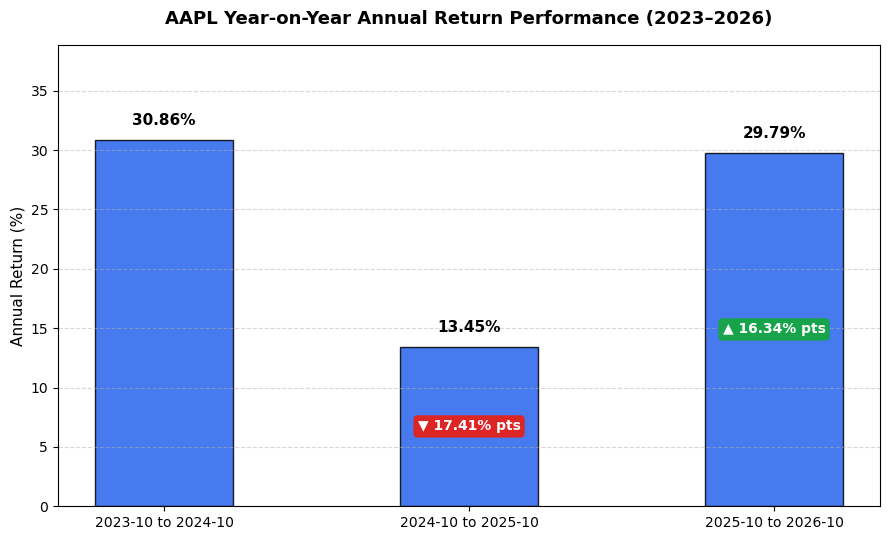

In [74]:
# 5. Visualise with Matplotlib
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(chart_df['period'], chart_df['annual_return'], color='#2563EB', width=0.45, edgecolor='black', alpha=0.85)

# Value Labels and Trend Comparison
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 1.0, f"{height:.2f}%", 
            ha='center', va='bottom', fontweight='bold', fontsize=11)
    
    # Compare with previous period bar
    if i > 0:
        diff = chart_df.loc[i, 'diff_pct_points']
        trend_symbol = "▲" if diff > 0 else "▼"
        trend_color = "#16A34A" if diff > 0 else "#DC2626"
        ax.annotate(
            f"{trend_symbol} {abs(diff):.2f}% pts",
            xy=(bar.get_x() + bar.get_width() / 2, height / 2),
            ha='center', va='center',
            color='white', fontweight='bold', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.3', facecolor=trend_color, edgecolor='none')
        )

ax.set_title("AAPL Year-on-Year Annual Return Performance (2023–2026)", fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel("Annual Return (%)", fontsize=11)
ax.set_ylim(0, max(chart_df['annual_return']) + 8)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
fig.savefig("images/annual_returns.png", dpi=300, bbox_inches="tight")
plt.show()